# 07 · Fine-tuning with Hugging Face: SFT, LoRA and distillation

A pretrained *instruct* model already chats, but it does not know **your** task, your output format or your conventions. Supervised fine-tuning (SFT) teaches it from (prompt → answer) examples.

| stage | data | objective | library |
|---|---|---|---|
| **SFT** (this notebook) | (prompt → response) pairs | next-token loss on the *response only* | `trl.SFTTrainer` |
| **LoRA** (this notebook) | same | same, but train small low-rank adapters | `peft.LoraConfig` |
| **distillation** (this notebook) | prompts labelled by a bigger teacher | SFT on the teacher's answers | `trl.SFTTrainer` |
| preferences (DPO) | (prompt, chosen, rejected) | prefer chosen over rejected | `trl.DPOTrainer` (notebook 08) |
| RL with verifiable rewards (GRPO) | prompts + a checker | maximize reward | `trl.GRPOTrainer` (notebook 08) |

**The task.** Turn a booking request written by a person into strict JSON:

`"Can you reserve Casa Lola for three people this Friday at 8:30 pm? It's under Rocio."` → `{"name": "Rocio", "restaurant": "Casa Lola", "people": 3, "day": "friday", "time": "20:30"}`

It looks easy, but the format is strict: `people` must be an integer (people write "three"), `day` lowercase, and `time` in 24-hour format (people write "8:30 pm" or "8 in the evening"). That last conversion is the hard part for a small model, and you will see it in every result below.

**The model.** `HuggingFaceTB/SmolLM2-135M-Instruct` (135 M parameters), small enough to fine-tune in a minute on a laptop GPU. The same code works unchanged for a 7B model on a bigger GPU.

**Plan:** chat templates and loss masking → baseline → full SFT vs LoRA → the "new special token" trap → rank ablation → distillation from a 360M teacher → evaluation.

In [1]:
import os, sys, json, time, random, re, gc, copy, tempfile, warnings
ROOT = os.path.abspath(".")
while not os.path.isdir(os.path.join(ROOT, "llm_edu_suite")) and os.path.dirname(ROOT) != ROOT:
    ROOT = os.path.dirname(ROOT)                    # walk up from notebooks/<topic>/ to the repo root
sys.path.insert(0, ROOT)
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
import torch
import transformers, peft, trl, datasets
from transformers import AutoTokenizer, AutoModelForCausalLM, set_seed
transformers.utils.logging.set_verbosity_error()   # keep the notebook output to what we print ourselves
transformers.utils.logging.disable_progress_bar()
datasets.disable_progress_bars()
import huggingface_hub; huggingface_hub.utils.logging.set_verbosity_error()
set_seed(0)

device = "cuda" if torch.cuda.is_available() else "cpu"
BF16 = device == "cuda" and torch.cuda.is_bf16_supported()
DTYPE = torch.bfloat16 if BF16 else torch.float32
# We share the GPU with Ollama, so we give this notebook a fixed VRAM budget. Going over it raises an
# out-of-memory error right away instead of silently spilling into (very slow) system RAM.
VRAM_BUDGET_GB = float(os.environ.get("VRAM_BUDGET_GB", 1.5))
if device == "cuda":
    total = torch.cuda.get_device_properties(0).total_memory / 1e9
    torch.cuda.set_per_process_memory_fraction(min(1.0, VRAM_BUDGET_GB / total))
    print(f"GPU: {torch.cuda.get_device_name(0)} ({total:.1f} GB), bf16: {BF16}, budget for this notebook: {VRAM_BUDGET_GB} GB")
else:
    print("No GPU found: running on CPU (expect it to be much slower)")
print("torch", torch.__version__, "| transformers", transformers.__version__, "| peft", peft.__version__, "| trl", trl.__version__)

def from_pretrained(cls, name, **kw):
    """Load from the local Hugging Face cache when the model is there, and download it otherwise."""
    try:
        return cls.from_pretrained(name, local_files_only=True, **kw)
    except OSError:
        return cls.from_pretrained(name, **kw)

def free():
    gc.collect()
    if device == "cuda":
        torch.cuda.empty_cache()

def reset_peak():
    if device == "cuda":
        torch.cuda.reset_peak_memory_stats()

def peak_gb():
    return torch.cuda.max_memory_allocated() / 1e9 if device == "cuda" else float("nan")

GPU: NVIDIA GeForce RTX 3060 Laptop GPU (6.4 GB), bf16: True, budget for this notebook: 1.5 GB
torch 2.14.1+cu130 | transformers 5.22.2 | peft 0.21.2 | trl 1.17.1


## 1. The task and the data

We generate the data, so we know the right answer for every example and can measure exactly. The **test set uses names and restaurants that never appear in training**, so a model that memorised the training set gets no credit. 300 labelled examples is our whole labelled budget (think of it as what a team can label by hand in an afternoon).

In [2]:
TRAIN_NAMES = ["Ana", "Luis", "Marta", "Pablo", "Sofia", "Diego", "Elena", "Jorge", "Lucia", "Carlos", "Irene", "Tomas",
               "Nuria", "Raul", "Clara", "Hugo", "Paula", "Adrian", "Sara", "Mario", "Laura", "Ivan", "Julia", "Victor"]
TEST_NAMES = ["Beatriz", "Oscar", "Alba", "Marcos", "Noelia", "Gonzalo", "Rocio", "Felipe", "Ines", "Samuel"]
TRAIN_PLACES = ["Casa Pepe", "La Tagliatella", "Sushi Zen", "El Faro", "Burger Hub", "Taco Loco", "Le Petit Bistro",
                "Green Garden", "La Brasa", "Mar Azul", "Pizza Napoli", "The Golden Duck", "Curry House", "El Rincon"]
TEST_PLACES = ["Asador Toro", "Bella Vista", "Noodle Bar", "Casa Lola", "The Oak Room", "Kebab Palace", "Ramen Ya"]
DAYS = ["monday", "tuesday", "wednesday", "thursday", "friday", "saturday", "sunday"]
NUM_WORDS = {2: "two", 3: "three", 4: "four", 5: "five", 6: "six", 7: "seven", 8: "eight", 9: "nine", 10: "ten"}
TEMPLATES = [
    "Hi, I'd like to book a table for {people} at {place} on {day} at {time}. The name is {name}.",
    "Can you reserve {place} for {people} people this {day} at {time}? It's under {name}.",
    "{name} here. Table for {people} at {place}, {day}, {time} please.",
    "Please make a reservation at {place}: {people} guests, {day} {time}, name {name}.",
    "We are {people}. Could we get a table at {place} on {day} around {time}? Booking for {name}.",
    "Book {place} for {name}, party of {people}, {day} at {time}.",
]
SYSTEM = "Extract the booking as JSON: name, restaurant, people (int), day (lowercase), time (24h HH:MM)."
FIELDS = ["name", "restaurant", "people", "day", "time"]

def time_text(h, m, rng):
    """The same time written the way people write it: 8pm, 8:30 pm, 20:30 or 8 in the evening."""
    h12 = h - 12 if h > 12 else h
    return [f"{h12}{':%02d' % m if m else ''}pm", f"{h12}:{m:02d} pm", f"{h:02d}:{m:02d}",
            f"{h12}{':%02d' % m if m else ''} in the evening"][rng.randrange(4)]

def make_booking(rng, names, places):
    people, h, m = rng.randint(2, 10), rng.randint(13, 22), rng.choice([0, 0, 15, 30, 45])
    target = {"name": rng.choice(names), "restaurant": rng.choice(places), "people": people,
              "day": rng.choice(DAYS), "time": f"{h:02d}:{m:02d}"}
    text = rng.choice(TEMPLATES).format(
        people=NUM_WORDS[people] if rng.random() < 0.4 else str(people), place=target["restaurant"],
        day=target["day"].capitalize() if rng.random() < 0.7 else target["day"], time=time_text(h, m, rng), name=target["name"])
    return text, target

def booking_examples(n, seed, split="train"):
    rng = random.Random(seed)
    names, places = (TRAIN_NAMES, TRAIN_PLACES) if split == "train" else (TEST_NAMES, TEST_PLACES)
    return [make_booking(rng, names, places) for _ in range(n)]

def to_prompt_completion(text, target, system=SYSTEM):
    """TRL's conversational prompt-completion format: the loss will only cover the completion."""
    return {"prompt": [{"role": "system", "content": system}, {"role": "user", "content": text}],
            "completion": [{"role": "assistant", "content": json.dumps(target)}]}

train_pairs = booking_examples(300, seed=0)                 # our labelled budget
test_pairs = booking_examples(40, seed=1, split="test")     # held out: unseen names and restaurants
train_rows = [to_prompt_completion(x, y) for x, y in train_pairs]
for x, y in train_pairs[:3]:
    print(x, "\n   ->", json.dumps(y))

Please make a reservation at La Brasa: 8 guests, thursday 7 in the evening, name Lucia. 
   -> {"name": "Lucia", "restaurant": "La Brasa", "people": 8, "day": "thursday", "time": "19:00"}
Can you reserve Sushi Zen for 7 people this Wednesday at 22:00? It's under Paula. 
   -> {"name": "Paula", "restaurant": "Sushi Zen", "people": 7, "day": "wednesday", "time": "22:00"}
Hi, I'd like to book a table for 10 at La Tagliatella on Saturday at 10 in the evening. The name is Carlos. 
   -> {"name": "Carlos", "restaurant": "La Tagliatella", "people": 10, "day": "saturday", "time": "22:00"}


**Metrics** (computed on the 40 held-out requests, greedy decoding):
- **JSON valid**: the reply contains a JSON object that parses.
- **exact match**: every field is right. This is the number that matters in production, because one wrong field is a wrong booking.
- **field accuracy**: the fraction of fields that are right (partial credit), plus the accuracy of `time` alone, the hardest field.

In [3]:
def parse_json(reply):
    m = re.search(r"\{.*\}", reply, re.S)
    try:
        obj = json.loads(m.group(0)) if m else None
    except json.JSONDecodeError:
        return None
    return obj if isinstance(obj, dict) else None

def score(replies, pairs=None):
    pairs = pairs or test_pairs
    objs = [parse_json(r) for r in replies]
    return {"valid": np.mean([o is not None for o in objs]),
            "exact": np.mean([o == y for o, (_, y) in zip(objs, pairs)]),
            "fields": np.mean([np.mean([(o or {}).get(k) == v for k, v in y.items()]) for o, (_, y) in zip(objs, pairs)]),
            "time": np.mean([(o or {}).get("time") == y["time"] for o, (_, y) in zip(objs, pairs)])}

@torch.no_grad()
def generate(model, tok, prompts, max_new_tokens=64, batch_size=20, skip_special_tokens=True):
    """Greedy replies for a list of chat prompts, in batches (left padding so every prompt ends at the same position)."""
    model.eval(); tok.padding_side = "left"; out = []
    for i in range(0, len(prompts), batch_size):
        enc = tok.apply_chat_template(prompts[i:i + batch_size], add_generation_prompt=True, return_tensors="pt",
                                      return_dict=True, padding=True).to(model.device)
        ids = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False, pad_token_id=tok.pad_token_id)
        out += tok.batch_decode(ids[:, enc["input_ids"].shape[1]:], skip_special_tokens=skip_special_tokens)
    return out

RESULTS = {}      # name -> metrics, filled by evaluate()
def evaluate(model, tok, name, prompts=None, show=0):
    replies = generate(model, tok, prompts or [to_prompt_completion(x, y)["prompt"] for x, y in test_pairs])
    RESULTS[name] = s = score(replies)
    print(f"{name:34s} valid {100*s['valid']:5.1f}% | exact {100*s['exact']:5.1f}% | fields {100*s['fields']:5.1f}% | time {100*s['time']:5.1f}%")
    for r in replies[:show]:
        print("    ", r[:150].replace("\n", " "))
    return replies

## 2. Chat templates and loss masking

An instruct model was trained on conversations rendered with a **chat template**: special tokens mark who is speaking. SmolLM2 uses the ChatML format (`<|im_start|>role ... <|im_end|>`). Fine-tuning must use *exactly* the same template the model will see at inference, so we never build the strings by hand: `tokenizer.apply_chat_template` does it.

In [4]:
MODEL = "HuggingFaceTB/SmolLM2-135M-Instruct"
tok = from_pretrained(AutoTokenizer, MODEL)
ex = train_rows[0]
print(tok.apply_chat_template(ex["prompt"] + ex["completion"], tokenize=False))

<|im_start|>system
Extract the booking as JSON: name, restaurant, people (int), day (lowercase), time (24h HH:MM).<|im_end|>
<|im_start|>user
Please make a reservation at La Brasa: 8 guests, thursday 7 in the evening, name Lucia.<|im_end|>
<|im_start|>assistant
{"name": "Lucia", "restaurant": "La Brasa", "people": 8, "day": "thursday", "time": "19:00"}<|im_end|>



**Loss masking.** We want the model to learn to *write the answer*, not to predict the system prompt or the user's sentence (that would waste capacity and teach it to imitate users). So the labels of every prompt token are set to `-100`, which PyTorch's cross-entropy ignores, and the loss only covers the assistant's reply **including its end-of-turn token `<|im_end|>`**, so the model also learns when to stop.

In TRL you get this by giving the dataset a `prompt` / `completion` split (`completion_only_loss`, the default for that format). For multi-turn chats there is `SFTConfig(assistant_only_loss=True)`, which needs a chat template with `{% generation %}` markers (TRL ships patched templates for common model families).

Under the hood it is just this:

In [5]:
def completion_labels(tokenizer, prompt, completion):
    """Tokenize prompt + completion with the chat template; mask every prompt token with -100."""
    prompt_ids = tokenizer.apply_chat_template(prompt, add_generation_prompt=True, tokenize=True, return_dict=True)["input_ids"]
    full_ids = tokenizer.apply_chat_template(prompt + completion, tokenize=True, return_dict=True)["input_ids"]
    assert full_ids[:len(prompt_ids)] == prompt_ids          # the prompt must be a prefix of the full conversation
    return full_ids, [-100] * len(prompt_ids) + full_ids[len(prompt_ids):]

ids, labels = completion_labels(tok, ex["prompt"], ex["completion"])
n_learn = sum(l != -100 for l in labels)
print(f"{len(ids)} tokens, {n_learn} with a loss ({100*n_learn/len(ids):.0f}%), {len(ids) - n_learn} masked\n")
n_prompt = len(ids) - n_learn
show = list(range(n_prompt - 8, n_prompt + 6)) + list(range(len(ids) - 4, len(ids)))
print("around the prompt/answer boundary and at the end:   · = masked (label -100)   ✓ = trained")
for i in show:
    print(f"   {i:3d} {'✓' if labels[i] != -100 else '·'}  {tok.decode([ids[i]])!r}" + ("   ..." if i == n_prompt + 5 else ""))

110 tokens, 42 with a loss (38%), 68 masked

around the prompt/answer boundary and at the end:   · = masked (label -100)   ✓ = trained
    60 ·  'ia'
    61 ·  '.'
    62 ·  '<|im_end|>'
    63 ·  '\n'
    64 ·  '<|im_start|>'
    65 ·  'ass'
    66 ·  'istant'
    67 ·  '\n'
    68 ✓  '{"'
    69 ✓  'name'
    70 ✓  '":'
    71 ✓  ' "'
    72 ✓  'Luc'
    73 ✓  'ia'   ...
   106 ✓  '0'
   107 ✓  '"}'
   108 ✓  '<|im_end|>'
   109 ✓  '\n'


Let's check that TRL builds exactly the same labels. `SFTTrainer` tokenizes the dataset when it is created, so we can inspect its `train_dataset` before training anything.

In [6]:
from datasets import Dataset
from trl import SFTConfig, SFTTrainer
from transformers import PrinterCallback

OUT = os.path.join(tempfile.gettempdir(), "llm_edu_07")
base = from_pretrained(AutoModelForCausalLM, MODEL, dtype=DTYPE).to(device)
probe = SFTTrainer(model=base, args=SFTConfig(output_dir=OUT, report_to="none", max_length=256, bf16=BF16, gradient_checkpointing=False),
                   train_dataset=Dataset.from_list(train_rows), processing_class=tok)
row = probe.train_dataset[0]
print("columns after TRL's preprocessing:", probe.train_dataset.column_names)
print("TRL's labels == our labels:", row["input_ids"] == ids and row["labels"] == labels)
del probe

columns after TRL's preprocessing: ['prompt', 'completion', 'input_ids', 'labels']
TRL's labels == our labels: True


## 3. Baseline: the instruct model before fine-tuning

Always measure the model before training, on the same test set, with the best prompt you can write. Here we try zero-shot (system prompt only) and **few-shot** (four solved examples in the conversation). Few-shot is the strong baseline that fine-tuning has to beat.

In [7]:
def few_shot_prompt(text, shots=booking_examples(4, seed=123)):
    msgs = [{"role": "system", "content": SYSTEM}]
    for x, y in shots:
        msgs += [{"role": "user", "content": x}, {"role": "assistant", "content": json.dumps(y)}]
    return msgs + [{"role": "user", "content": text}]

_ = evaluate(base, tok, "baseline zero-shot", show=1)
_ = evaluate(base, tok, "baseline few-shot", prompts=[few_shot_prompt(x) for x, _ in test_pairs], show=2)
del base; free()

baseline zero-shot                 valid   5.0% | exact   0.0% | fields   2.0% | time   0.0%
     Asador Toro: 4 guests, Thursday 10:00 pm, name Noelia.


baseline few-shot                  valid 100.0% | exact  17.5% | fields  73.0% | time  25.0%
     {"name": "Noelia", "restaurant": "Asador Toro", "people": 4, "day": "Thursday", "time": "10:00 pm"}
     {"name": "Rocio", "restaurant": "Casa Lola", "people": 3, "day": "Friday", "time": "8:00 pm"}


Zero-shot, the 135M model almost never produces JSON (5 %): it mostly rephrases the request. With four examples it always produces valid JSON, but the normalization is often wrong (`"Thursday"`, `"10:00 pm"`): 17.5 % exact. That is our bar.

## 4. Full fine-tuning vs LoRA

### 4.1 How much memory does full fine-tuning need?

With mixed precision and AdamW, every trainable parameter costs about **16 bytes**: fp32 weight (4) + gradient (4) + Adam's two moments (8), before activations. For 135 M parameters that is 2.2 GB, already above this notebook's budget; for a 7B model it is 112 GB. Two standard ways out:
- cheaper optimizer state and bf16 weights (here: bf16 weights + **Adafactor**, which stores a factored second moment and no first moment), or
- train far fewer parameters: **LoRA**.

One helper runs every training in this notebook so they are comparable: same data, same 2 epochs, effective batch 16, cosine schedule, bf16, gradient checkpointing.

In [8]:
RUNS = {}         # name -> training time, peak VRAM, trainable parameters, loss curve

def train_sft(model, rows, name, peft_config=None, lr=1e-3, epochs=2, micro_batch=8, optim="adamw_torch", tokenizer=None):
    cfg = SFTConfig(output_dir=OUT, num_train_epochs=epochs, learning_rate=lr, lr_scheduler_type="cosine", warmup_steps=5,
                    per_device_train_batch_size=micro_batch, gradient_accumulation_steps=16 // micro_batch,
                    optim=optim, bf16=BF16, gradient_checkpointing=True, max_length=256,
                    logging_steps=2, save_strategy="no", report_to="none", disable_tqdm=True, seed=0)
    trainer = SFTTrainer(model=model, args=cfg, train_dataset=Dataset.from_list(rows),
                         processing_class=tokenizer or tok, peft_config=peft_config)
    trainer.remove_callback(PrinterCallback)              # we plot the logs instead of printing them
    n_train = sum(p.numel() for p in trainer.model.parameters() if p.requires_grad)
    reset_peak(); t0 = time.time()
    trainer.train()
    RUNS[name] = {"time": time.time() - t0, "peak": peak_gb(), "trainable": n_train,
                  "loss": [(h["step"], h["loss"]) for h in trainer.state.log_history if "loss" in h]}
    print(f"{name}: {n_train/1e6:.1f} M trainable params, {trainer.state.global_step} steps, "
          f"{RUNS[name]['time']:.0f} s, peak VRAM {RUNS[name]['peak']:.2f} GB, final loss {RUNS[name]['loss'][-1][1]:.3f}")
    return trainer

full_model = from_pretrained(AutoModelForCausalLM, MODEL, dtype=DTYPE).to(device)
trainer = train_sft(full_model, train_rows, "full SFT", lr=1e-4, micro_batch=4, optim="adafactor")
_ = evaluate(trainer.model, tok, "full SFT", show=2)
del trainer, full_model; free()

full SFT: 134.5 M trainable params, 38 steps, 44 s, peak VRAM 1.19 GB, final loss 0.039


full SFT                           valid 100.0% | exact  35.0% | fields  85.5% | time  37.5%
     {"name": "Noelia", "restaurant": "Asador Toro", "people": 4, "day": "thursday", "time": "13:00"}
     {"name": "Rocio", "restaurant": "Casa Lola", "people": 3, "day": "friday", "time": "17:00"}


### 4.2 LoRA: Low-Rank Adaptation

Freeze the pretrained weight `W` and learn a low-rank update:
$$W' = W + \tfrac{\alpha}{r}\,BA,\qquad A\in\mathbb{R}^{r\times k},\ B\in\mathbb{R}^{d\times r},\ B=0 \text{ at init}$$

- only `A` and `B` are trained (a few % of the parameters), so gradients and optimizer state shrink accordingly;
- `B = 0` at init, so the model starts *exactly* as the base model;
- after training, `merge_and_unload()` folds `BA` into `W`: zero extra latency at inference;
- adapters are tiny files: one base model can serve many tasks by swapping adapters.

`peft.LoraConfig` choices: `r` (rank), `lora_alpha` (scale; `alpha = 2r` is a common default), and `target_modules`. `"all-linear"` (q, k, v, o, gate, up, down) usually beats a larger rank on q/v only. LoRA wants a **higher learning rate** than full fine-tuning (1e-4 to 1e-3 instead of 1e-5 to 1e-4), because `B` starts at zero and the update is scaled by `alpha / r`.

In [9]:
from peft import LoraConfig, get_peft_model

lora_cfg = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.0, target_modules="all-linear", task_type="CAUSAL_LM")
lora_model = get_peft_model(from_pretrained(AutoModelForCausalLM, MODEL, dtype=DTYPE).to(device), lora_cfg)
lora_model.print_trainable_parameters()
print("adapted modules:", sorted(lora_model.peft_config["default"].target_modules))

x = tok.apply_chat_template(train_rows[0]["prompt"], add_generation_prompt=True, return_tensors="pt", return_dict=True).to(device)
with torch.no_grad():
    with lora_model.disable_adapter():
        logits_base = lora_model(**x).logits
    logits_lora = lora_model(**x).logits
print("identical to the base model at init (B = 0):", torch.equal(logits_base, logits_lora))

trainable params: 4,884,480 || all params: 139,399,488 || trainable%: 3.5039
adapted modules: ['down_proj', 'gate_proj', 'k_proj', 'o_proj', 'q_proj', 'up_proj', 'v_proj']
identical to the base model at init (B = 0): True


In [10]:
trainer = train_sft(lora_model, train_rows, "LoRA r=16")
_ = evaluate(trainer.model, tok, "LoRA r=16", show=2)

adapter_dir = os.path.join(OUT, "lora_r16")
trainer.model.save_pretrained(adapter_dir)
size_mb = sum(os.path.getsize(os.path.join(adapter_dir, f)) for f in os.listdir(adapter_dir)) / 1e6
print(f"adapter on disk: {size_mb:.1f} MB (the full model in bf16 is {2 * 134.5:.0f} MB)")

del trainer, lora_model; free()

# Merging: load the saved adapter on top of a fresh base model (in fp32, on the CPU), then fold B·A into W.
from peft import PeftModel
xc = {k: v.cpu() for k, v in x.items()}
reloaded = PeftModel.from_pretrained(from_pretrained(AutoModelForCausalLM, MODEL, dtype=torch.float32), adapter_dir)
with torch.no_grad():
    before = reloaded(**xc).logits
merged = reloaded.merge_and_unload()                   # a plain LlamaForCausalLM again, no LoRA modules left
with torch.no_grad():
    after = merged(**xc).logits
print(f"merged in fp32 -> {type(merged).__name__}: max |logit change| = {(before - after).abs().max().item():.1e}, "
      f"same greedy token at every position: {torch.equal(before.argmax(-1), after.argmax(-1))}")
del reloaded, merged

LoRA r=16: 4.9 M trainable params, 38 steps, 39 s, peak VRAM 1.41 GB, final loss 0.039


LoRA r=16                          valid 100.0% | exact  32.5% | fields  86.5% | time  32.5%
     {"name": "Noelia", "restaurant": "Asador Toro", "people": 4, "day": "thursday", "time": "10:00"}
     {"name": "Rocio", "restaurant": "Casa Lola", "people": 3, "day": "friday", "time": "18:00"}


adapter on disk: 19.6 MB (the full model in bf16 is 269 MB)


merged in fp32 -> LlamaForCausalLM: max |logit change| = 1.0e-04, same greedy token at every position: True


**What we see.** Both full SFT and LoRA turn a model that needed four examples in its prompt into one that always produces valid JSON with the right names, restaurants, party sizes and days (field accuracy ≈ 86 % against 73 % few-shot), and both double the few-shot exact match. The remaining errors are almost all in `time`: with 300 examples and 2 epochs the 12-hour → 24-hour conversion ("10 pm" → "22:00") is only partly learned; the models often copy the hour (`10:00`) or guess one. LoRA trains 3.5 % of the parameters and lands within one test request of full fine-tuning (32.5 % vs 35.0 % exact). Its adapter is a 20 MB file.

About memory: full fine-tuning fitted only because we switched to bf16 weights and Adafactor (1.19 GB peak at micro-batch 4). LoRA r=16 peaked at 1.41 GB, but with micro-batch 8; at micro-batch 4 a LoRA run needs about 0.9 GB (see the first run in section 5). In a model this small, activations and the 49k-token output layer weigh as much as the weights, so the gap is modest. It grows with model size: for a 7B model, full fine-tuning with AdamW needs ~112 GB for weights, gradients and optimizer state, while LoRA needs little more than the 14 GB of frozen bf16 weights.

## 5. The "new special token" trap

Real projects often **add tokens**: a new role, a tool-call marker, a `<|json|>` tag. `tokenizer.add_tokens` + `model.resize_token_embeddings` adds rows to the embedding matrix. Transformers initializes them at the **mean** of the existing embeddings (plus tiny noise).

Now combine that with LoRA, which freezes the embeddings. SmolLM2 ties the input embedding and the output layer (`lm_head`): the logit of token *i* is $h \cdot e_i$. A vector at the mean of all $e_i$ lies *inside* the cloud of embeddings, and a linear score $h \cdot e$ is always maximized at the edge of the cloud, never at its centre. So **no hidden state can ever make the new token the most likely one**: greedy decoding can never emit it, however well the adapters train. The fix is to train the embedding row too: `LoraConfig(modules_to_save=["embed_tokens"], ensure_weight_tying=True)` (the whole matrix, tied to `lm_head`) or `trainable_token_indices=[...]` (only the new rows).

Experiment: the answer must now start with a new `<|json|>` token. Same data, LoRA r=16 with and without a trainable embedding.

In [11]:
MARK = "<|json|>"
tok_mark = from_pretrained(AutoTokenizer, MODEL)
tok_mark.add_tokens([MARK], special_tokens=True)
mark_id = tok_mark.convert_tokens_to_ids(MARK)
mark_rows = [{"prompt": r["prompt"], "completion": [{"role": "assistant", "content": MARK + r["completion"][0]["content"]}]}
             for r in train_rows]

def model_with_marker():
    m = from_pretrained(AutoModelForCausalLM, MODEL, dtype=DTYPE).to(device)
    m.resize_token_embeddings(len(tok_mark))
    return m

m = model_with_marker()
E = m.get_input_embeddings().weight.float()
print(f"new token id {mark_id}: distance to the mean embedding {(E[mark_id] - E[:mark_id].mean(0)).norm():.4f} "
      f"(a typical embedding has norm {E[:mark_id].norm(dim=-1).mean():.2f}); tied lm_head: {m.config.tie_word_embeddings}")
del m, E; free()

def marker_eval(model, name):
    prompts = [to_prompt_completion(x, y)["prompt"] for x, y in test_pairs]
    replies = generate(model, tok_mark, prompts, skip_special_tokens=False)
    enc = tok_mark.apply_chat_template(prompts, add_generation_prompt=True, return_tensors="pt", return_dict=True, padding=True).to(device)
    with torch.no_grad():                                    # the distribution over the first token of the answer
        first = model(**enc, logits_to_keep=1).logits[:, -1].float()
    rank = (first > first[:, mark_id:mark_id + 1]).sum(-1).float().mean().item()
    starts = np.mean([r.startswith(MARK) for r in replies])
    exact = np.mean([r.startswith(MARK) and parse_json(r) == y for r, (_, y) in zip(replies, test_pairs)])
    MARKER[name] = {"starts": starts, "exact": exact, "rank": rank, "p": first.softmax(-1)[:, mark_id].mean().item()}
    print(f"{name:32s} starts with {MARK}: {100*starts:5.1f}% | exact (marker + JSON): {100*exact:5.1f}% | "
          f"rank of {MARK} as first token: {rank:7.0f} | its probability: {MARKER[name]['p']:.4f}")
    print("    ", replies[0][:120].replace("\n", " "))

MARKER = {}
cfg_plain = LoraConfig(r=16, lora_alpha=32, target_modules="all-linear", task_type="CAUSAL_LM")
trainer = train_sft(model_with_marker(), mark_rows, "LoRA, frozen embeddings", peft_config=cfg_plain, micro_batch=4, tokenizer=tok_mark)
marker_eval(trainer.model, "LoRA, frozen embeddings")
del trainer; free()

cfg_emb = LoraConfig(r=16, lora_alpha=32, target_modules="all-linear", task_type="CAUSAL_LM",
                     modules_to_save=["embed_tokens"], ensure_weight_tying=True)
trainer = train_sft(model_with_marker(), mark_rows, "LoRA + trainable embeddings", peft_config=cfg_emb, micro_batch=4, tokenizer=tok_mark)
marker_eval(trainer.model, "LoRA + trainable embeddings")
del trainer; free()

new token id 49152: distance to the mean embedding 0.0034 (a typical embedding has norm 3.20); tied lm_head: True


LoRA, frozen embeddings: 4.9 M trainable params, 38 steps, 74 s, peak VRAM 0.90 GB, final loss 0.300


LoRA, frozen embeddings          starts with <|json|>:   0.0% | exact (marker + JSON):   0.0% | rank of <|json|> as first token:   24296 | its probability: 0.0000
     lr:lr＋＋＋＋＋＋＋＋＋＋＋＋＋＋＋＋＋＋＋＋＋＋＋＋＋＋＋＋＋＋�


LoRA + trainable embeddings: 33.2 M trainable params, 38 steps, 74 s, peak VRAM 1.24 GB, final loss 0.035


LoRA + trainable embeddings      starts with <|json|>: 100.0% | exact (marker + JSON):  32.5% | rank of <|json|> as first token:       0 | its probability: 0.9265
     <|json|>{"name": "Noelia", "restaurant": "Asador Toro", "people": 4, "day": "thursday", "time": "10:00"}<|im_end|><|im_e


The theory holds on a real model. With frozen embeddings, `<|json|>` is never emitted: as the first token of the answer it ranks around 24,000th in the vocabulary, with probability ≈ 0. Worse, the training loss stays high (0.30 against 0.035) and the model degenerates: it learned to start the answer with *something* where the marker should be, and now emits garbage. With a trainable embedding the marker is the top token (p ≈ 0.93), it starts 100 % of the answers, and the JSON quality is back to plain LoRA (32.5 % exact).

Two practical notes:
- `trainable_token_indices=[mark_id]` trains only the new row (a few hundred parameters instead of the whole 28 M-parameter matrix). With the versions used here (`trl` 1.17, `peft` 0.21), it fails inside `SFTTrainer` on a tied `lm_head` (`TrainableTokensWrapper` has no `bias` for TRL's fused loss). That is why we use `modules_to_save`. Check again when you upgrade.
- The same trap appears when you fine-tune a *base* model with a chat template whose tokens (`<|im_start|>`, `<|eot_id|>`…) it has never seen: train the embeddings, or start from a model that already knows the template.

## 6. Rank ablation: how much rank do you need?

The LoRA paper found that very small ranks (1–8) often match full fine-tuning. We train r = 2, 16 (above) and 64 with the same data and steps (`alpha = 2r`, so the effective scale `alpha/r` stays the same).

LoRA r=2: 0.6 M trainable params, 38 steps, 38 s, peak VRAM 1.35 GB, final loss 0.054


LoRA r=2                           valid 100.0% | exact  20.0% | fields  80.5% | time  30.0%


LoRA r=64: 19.5 M trainable params, 38 steps, 74 s, peak VRAM 1.13 GB, final loss 0.032


LoRA r=64                          valid 100.0% | exact  45.0% | fields  89.0% | time  45.0%


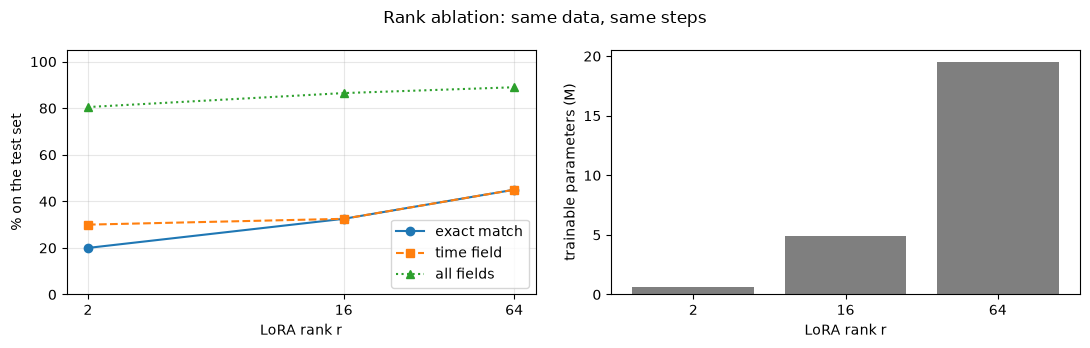

In [12]:
for r in [2, 64]:
    cfg = LoraConfig(r=r, lora_alpha=2 * r, target_modules="all-linear", task_type="CAUSAL_LM")
    trainer = train_sft(from_pretrained(AutoModelForCausalLM, MODEL, dtype=DTYPE).to(device), train_rows, f"LoRA r={r}",
                        peft_config=cfg, micro_batch=8 if r <= 16 else 4)     # same effective batch; r=64 needs more memory
    _ = evaluate(trainer.model, tok, f"LoRA r={r}")
    del trainer; free()

ranks = [2, 16, 64]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(ranks, [100 * RESULTS[f"LoRA r={r}"]["exact"] for r in ranks], "o-", label="exact match")
ax[0].plot(ranks, [100 * RESULTS[f"LoRA r={r}"]["time"] for r in ranks], "s--", label="time field")
ax[0].plot(ranks, [100 * RESULTS[f"LoRA r={r}"]["fields"] for r in ranks], "^:", label="all fields")
ax[0].set_xscale("log", base=2); ax[0].set_xticks(ranks, [str(r) for r in ranks]); ax[0].set_ylim(0, 105)
ax[0].set_xlabel("LoRA rank r"); ax[0].set_ylabel("% on the test set"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].bar([str(r) for r in ranks], [RUNS[f"LoRA r={r}"]["trainable"] / 1e6 for r in ranks], color="tab:gray")
ax[1].set_xlabel("LoRA rank r"); ax[1].set_ylabel("trainable parameters (M)")
fig.suptitle("Rank ablation: same data, same steps"); plt.tight_layout(); plt.show()

With the same data and steps, exact match rises with the rank here: 20 % (r = 2) → 32.5 % (r = 16) → 45 % (r = 64), almost all of it in the `time` field, and the training curves show r = 2 learning more slowly. Learning a new rule from 300 examples in 38 steps benefits from more adapter capacity. Two caveats: with 40 test requests each one is worth 2.5 points, so a difference of one or two requests is noise; and all three ranks stay far below what more data gives (next section). Common practice: start at r = 16 with `alpha = 2r` on all linear layers, and raise the rank only if the held-out metric asks for it.

## 7. Distillation: a bigger teacher labels the data

Labelled data is expensive, unlabelled prompts are cheap. **Knowledge distillation** transfers what a strong *teacher* knows into a small *student*. Two flavours:

- **Sequence-level (synthetic-data) distillation**: the teacher *writes the answers* to unlabelled prompts, and the student does ordinary SFT on them. This is how most small open models are made today (e.g. DeepSeek-R1-Distill, or fine-tuning on answers from a frontier API). It only needs the teacher's text.
- **Logit distillation**: the student matches the teacher's full next-token distribution at temperature τ, $\mathcal{L} = (1-\lambda)\,\mathrm{CE}(y, p_s) + \lambda\,\tau^2\,\mathrm{KL}(p_t^{\tau}\,\|\,p_s^{\tau})$. Denser signal ("dark knowledge": how likely every other token was), but it needs the teacher's logits and **the same tokenizer**. TRL implements the on-policy version (GKD) as `trl.DistillationTrainer`. We do not run it here to keep the notebook short.

Our setup: the teacher is **SmolLM2-360M-Instruct** fine-tuned with LoRA on the *same* 300 labelled examples. It then labels **600 new, unlabelled requests**, and the 135M student is trained on the 300 human labels plus the 600 teacher labels.

In [13]:
TEACHER = "HuggingFaceTB/SmolLM2-360M-Instruct"
teacher = from_pretrained(AutoModelForCausalLM, TEACHER, dtype=DTYPE).to(device)
cfg = LoraConfig(r=16, lora_alpha=32, target_modules="all-linear", task_type="CAUSAL_LM")
trainer = train_sft(teacher, train_rows, "teacher 360M LoRA r=16", peft_config=cfg, micro_batch=2)
teacher = trainer.model.merge_and_unload(); del trainer; free()
_ = evaluate(teacher, tok, "teacher 360M LoRA r=16")           # SmolLM2 135M and 360M share the same tokenizer

unlabelled = [x for x, _ in booking_examples(600, seed=7)]     # new requests; we pretend we do not know their answers
t0 = time.time()
teacher_replies = generate(teacher, tok, [to_prompt_completion(x, {})["prompt"] for x in unlabelled])
print(f"teacher labelled {len(unlabelled)} requests in {time.time() - t0:.0f} s")
hidden_gold = [y for _, y in booking_examples(600, seed=7)]   # only to measure the quality of the teacher's labels
print(f"teacher labels: {100*np.mean([parse_json(r) is not None for r in teacher_replies]):.1f}% valid JSON, "
      f"{100*np.mean([parse_json(r) == y for r, y in zip(teacher_replies, hidden_gold)]):.1f}% exactly right")
teacher_rows = [to_prompt_completion(x, parse_json(r)) for x, r in zip(unlabelled, teacher_replies) if parse_json(r) is not None]
del teacher; free()

cfg = LoraConfig(r=16, lora_alpha=32, target_modules="all-linear", task_type="CAUSAL_LM")
# One epoch over 300 + ~600 examples is 57 optimizer steps (vs 38 for the 135M runs above): 3x the data, 1.5x the steps.
trainer = train_sft(from_pretrained(AutoModelForCausalLM, MODEL, dtype=DTYPE).to(device), train_rows + teacher_rows,
                    "student 135M: human + teacher labels", peft_config=cfg, epochs=1)
_ = evaluate(trainer.model, tok, "student 135M: human + teacher labels", show=2)
del trainer; free()

teacher 360M LoRA r=16: 8.7 M trainable params, 38 steps, 161 s, peak VRAM 1.16 GB, final loss 0.012


teacher 360M LoRA r=16             valid 100.0% | exact  87.5% | fields  97.5% | time  92.5%


teacher labelled 600 requests in 72 s
teacher labels: 100.0% valid JSON, 90.0% exactly right


student 135M: human + teacher labels: 4.9 M trainable params, 57 steps, 65 s, peak VRAM 1.43 GB, final loss 0.027


student 135M: human + teacher labels valid 100.0% | exact  55.0% | fields  91.0% | time  55.0%
     {"name": "Noelia", "restaurant": "Asador Toro", "people": 4, "day": "thursday", "time": "13:00"}
     {"name": "Rocio", "restaurant": "Casa Lola", "people": 3, "day": "friday", "time": "21:00"}


**What happened.** Trained on the *same* 300 human labels, the 360M teacher reaches 87.5 % exact (92.5 % on `time`): the bigger model learns the conversion rule from data that was not enough for the 135M model. Its labels for the 600 new requests are 90 % exactly right. The 135M student trained on human + teacher labels goes from 32.5 % (human labels only, LoRA r = 16) to **55 %** exact. Two honest caveats: the comparison is not perfectly controlled (the student also took 57 optimizer steps instead of 38), and the student still trails its teacher and has learned from labels that are 10 % wrong. In real projects you cannot compute that 90 % for free as we did here: spot-check a sample of the teacher's labels, or filter them with a verifier (here, a JSON schema check would catch format errors but not a wrong hour).

## 8. Evaluation

Every model on the same 40 held-out requests, plus what each training run cost.

model                                   valid  exact  fields   time |  trainable  train s  peak GB
baseline zero-shot                         5%     0%      2%     0% |          -        -        -
baseline few-shot                        100%    18%     73%    25% |          -        -        -
full SFT                                 100%    35%     86%    38% |    134.5 M       44     1.19
LoRA r=2                                 100%    20%     80%    30% |      0.6 M       38     1.35
LoRA r=16                                100%    32%     86%    32% |      4.9 M       39     1.41
LoRA r=64                                100%    45%     89%    45% |     19.5 M       74     1.13
teacher 360M LoRA r=16                   100%    88%     98%    92% |      8.7 M      161     1.16
student 135M: human + teacher labels     100%    55%     91%    55% |      4.9 M       65     1.43


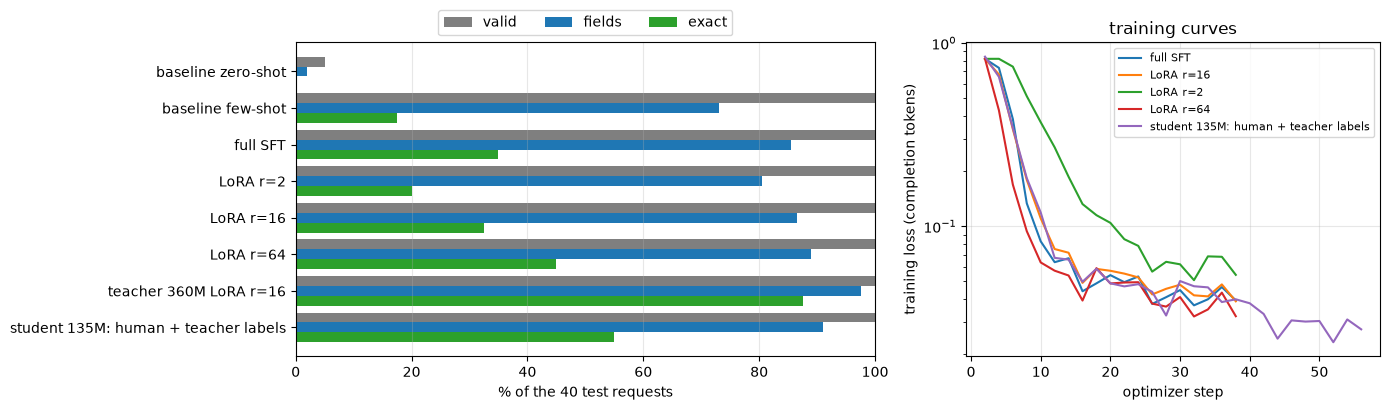

In [14]:
order = [n for n in ["baseline zero-shot", "baseline few-shot", "full SFT", "LoRA r=2", "LoRA r=16", "LoRA r=64",
                     "teacher 360M LoRA r=16", "student 135M: human + teacher labels"] if n in RESULTS]
print(f"{'model':38s} {'valid':>6s} {'exact':>6s} {'fields':>7s} {'time':>6s} | {'trainable':>10s} {'train s':>8s} {'peak GB':>8s}")
for n in order:
    r, run = RESULTS[n], RUNS.get(n)
    cost = f"{run['trainable']/1e6:8.1f} M {run['time']:8.0f} {run['peak']:8.2f}" if run else f"{'-':>10s} {'-':>8s} {'-':>8s}"
    print(f"{n:38s} {100*r['valid']:5.0f}% {100*r['exact']:5.0f}% {100*r['fields']:6.0f}% {100*r['time']:5.0f}% | {cost}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1.4, 1]})
ys = np.arange(len(order)); w = 0.27
for k, (metric, c) in enumerate([("valid", "tab:gray"), ("fields", "tab:blue"), ("exact", "tab:green")]):
    ax[0].barh(ys + (k - 1) * w, [100 * RESULTS[n][metric] for n in order], height=w, color=c, label=metric)
ax[0].set_yticks(ys, order); ax[0].invert_yaxis(); ax[0].set_xlim(0, 100); ax[0].set_xlabel("% of the 40 test requests")
ax[0].legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3); ax[0].grid(alpha=.3, axis="x")
for n in ["full SFT", "LoRA r=16", "LoRA r=2", "LoRA r=64", "student 135M: human + teacher labels"]:
    steps, loss = zip(*RUNS[n]["loss"])
    ax[1].plot(steps, loss, label=n)
ax[1].set_yscale("log"); ax[1].set_xlabel("optimizer step"); ax[1].set_ylabel("training loss (completion tokens)")
ax[1].set_title("training curves"); ax[1].grid(alpha=.3); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Reading the results.**
1. Fine-tuning beats the best prompt: few-shot gets 17.5 % exact; 300 examples and under a minute of training get 32–45 %, and every fine-tuned model writes valid JSON 100 % of the time.
2. LoRA (3.5 % of the parameters) is within one test request of full fine-tuning.
3. The biggest levers were **model size** (the 360M teacher: 87.5 %) and **more data**, even machine-labelled (the student: 55 %). Rank came next (20 → 45 %).
4. The per-field view says where to go next: almost all remaining errors are in `time`. That tells you to add examples of exactly that conversion, rather than more data in general.
5. The training curves end at similar losses (0.03–0.05) while held-out exact match ranges from 20 % to 45 %. Training loss alone does not tell you task accuracy.

With 40 test requests, each request is 2.5 points: treat differences of one or two requests as noise, and use a larger test set before making a real decision.

### What to measure in a real project

| check | why |
|---|---|
| exact match / task accuracy on *your* held-out set (built before training) | did it learn the task? |
| per-field or per-category breakdown | where are the remaining errors? (here: `time`) |
| JSON validity, or constrained decoding (`outlines`, `xgrammar`) | structured output must never break the caller |
| general benchmarks before/after (`lm-eval-harness`: MMLU, IFEval…) | catastrophic forgetting |
| training loss *and* held-out metric | a low training loss alone hides overfitting |

## Takeaways

- Use the model's **chat template** and mask the prompt: train only on the answer and its end-of-turn token. `trl.SFTTrainer` does it for prompt-completion data; check the labels once, as we did.
- Measure a **few-shot baseline** first. Fine-tuning has to beat a good prompt, not a bad one.
- **LoRA** (`target_modules="all-linear"`, a higher LR) trains a few % of the parameters, fits where full fine-tuning does not, merges back for free, and on small data is as good as full fine-tuning.
- **New tokens + frozen embeddings cannot work** with tied embeddings and mean initialization: make the embedding trainable (`modules_to_save` or `trainable_token_indices`).
- **Rank** helped here (20 → 45 % from r = 2 to r = 64), but much less than more data did. Start at r = 16 and let the held-out metric decide.
- **Sequence-level distillation**: a stronger teacher turns cheap unlabelled prompts into training data. The student is bounded by the teacher's mistakes, so measure the teacher's labels.

**Next:** `08_preference_rl_dpo_grpo.ipynb`: DPO and GRPO with TRL.